# Diabetes Readmission Prediction
## Patient-wise vs. Encounter-wise Split - Sudarshan Tiwari

### Objective
In `logistic_regression.ipynb` I split the data by patient, so every encounter of a patient lands in only
one of the training, validation or test sets. A teammate suggested testing how performance changes
*without* the patient-wise split. Their reasoning: the same patient can be readmitted after one encounter
and not after another, and a patient with many encounters (up to 40 here) who lands entirely in the
validation or test set is a pattern the model never gets to learn from.

Here I train the exact same logistic regression model, with the same cleaning and the same tuning steps,
and change only one thing: how the encounters are split.
* **Patient split** - `GroupShuffleSplit` by `patient_nbr` (what the main notebook and the Random Forest use).
* **Encounter split** - a plain stratified `train_test_split` on encounters, so one patient's encounters
  can end up in training, validation and test at the same time.

In [1]:
# Imports and load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (GroupShuffleSplit, train_test_split,
                                     StratifiedKFold, StratifiedGroupKFold, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

df = pd.read_csv('../Data/diabetic_data.csv')

## Same Data Preparation as the Main Notebook
These cells are copied unchanged from `logistic_regression.ipynb`: the same missing-value handling, the
same removal of expired patients, the same encoding and the same diagnosis grouping.

In [2]:
# Replace all ? with NaN so pandas recognizes them as missing values
df = df.replace('?', np.nan)

# Treat invalid gender entries as missing
df['gender'] = df['gender'].replace('Unknown/Invalid', np.nan)

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage Missing': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_summary = missing_summary[missing_summary['Missing Values'] > 0]
print(missing_summary.sort_values(by='Percentage Missing', ascending=False))

                   Missing Values  Percentage Missing
weight                      98569               96.86
max_glu_serum               96420               94.75
A1Cresult                   84748               83.28
medical_specialty           49949               49.08
payer_code                  40256               39.56
race                         2273                2.23
diag_3                       1423                1.40
diag_2                        358                0.35
diag_1                         21                0.02
gender                          3                0.00


In [3]:
# Drop attributes
df = df.drop(columns=['weight', 'payer_code', 'encounter_id'])

# Fill with a global constant
df[['max_glu_serum', 'A1Cresult']] = df[['max_glu_serum', 'A1Cresult']].fillna('Not measured')
fill_unknown = ['medical_specialty', 'race', 'diag_1', 'diag_2', 'diag_3']
df[fill_unknown] = df[fill_unknown].fillna('Unknown')

# Remove patients who expired (they cannot be readmitted)
df = df[~df['discharge_disposition_id'].isin([11, 19, 20, 21])]

# Target: 1 = readmitted within 30 days, 0 = otherwise
df['readmitted'] = (df['readmitted'] == '<30').astype(int)

print("Remaining missing values (only the 3 invalid gender rows):", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)
print(df['readmitted'].value_counts(normalize=True).mul(100).round(2))

Remaining missing values (only the 3 invalid gender rows): 3
Shape after cleaning: (100114, 47)
readmitted
0    88.66
1    11.34
Name: proportion, dtype: float64


In [4]:
# Ordinal attribute: age interval -> ordered code 0..9
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)',
             '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']
df['age'] = df['age'].map({a: i for i, a in enumerate(age_order)})

# Remember the 3 invalid-gender rows; they are removed after the split
valid_gender = df['gender'].notna()

# Binary attributes -> 0/1
df['change'] = (df['change'] == 'Ch').astype(int)
df['diabetesMed'] = (df['diabetesMed'] == 'Yes').astype(int)
df['gender'] = (df['gender'] == 'Male').astype(int)

# ID codes are nominal labels, not quantities
for col in ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']:
    df[col] = df[col].astype(str)

In [5]:
def diagnosis_group(code):
    # Generalize an ICD-9 code to its higher-level disease group (concept hierarchy)
    if code == 'Unknown':
        return 'Unknown'
    if code.startswith('V') or code.startswith('E'):
        return 'Other'
    value = float(code)
    if 390 <= value <= 459 or int(value) == 785:
        return 'Circulatory'
    if 460 <= value <= 519 or int(value) == 786:
        return 'Respiratory'
    if 520 <= value <= 579 or int(value) == 787:
        return 'Digestive'
    if int(value) == 250:
        return 'Diabetes'
    if 800 <= value <= 999:
        return 'Injury'
    if 710 <= value <= 739:
        return 'Musculoskeletal'
    if 580 <= value <= 629 or int(value) == 788:
        return 'Genitourinary'
    if 140 <= value <= 239:
        return 'Neoplasms'
    return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].apply(diagnosis_group)

df['diag_1'].value_counts()

diag_1
Circulatory        29881
Other              17887
Respiratory        14074
Digestive           9380
Diabetes            8693
Injury              6881
Genitourinary       5054
Musculoskeletal     4944
Neoplasms           3299
Unknown               21
Name: count, dtype: int64

In [6]:
single_value_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Dropping single-valued attributes:", single_value_cols)
df = df.drop(columns=single_value_cols)

numerical_columns = [
    'age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]
binary_columns = ['gender', 'change', 'diabetesMed']
categorical_columns = [c for c in df.columns
                       if c not in numerical_columns + binary_columns + ['readmitted', 'patient_nbr']]

print("Numerical:", len(numerical_columns), "| Binary:", len(binary_columns),
      "| Nominal:", len(categorical_columns))
print(categorical_columns)

Dropping single-valued attributes: ['examide', 'citoglipton']
Numerical: 9 | Binary: 3 | Nominal: 31
['race', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [7]:
def make_preprocessor():
    return ColumnTransformer(transformers=[
        ('numerical', StandardScaler(), numerical_columns),
        ('binary', 'passthrough', binary_columns),
        ('categorical', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=100), categorical_columns)
    ])

def make_model(C):
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('classifier', LogisticRegression(C=C, class_weight='balanced', max_iter=1000))
    ])

## How Many Encounters Does Each Patient Have?

In [8]:
X = df.drop(columns=['readmitted', 'patient_nbr'])
y = df['readmitted']
groups = df['patient_nbr']

# Number of encounters each patient has in the data
visits = groups.map(groups.value_counts())
per_patient = groups.value_counts()

print("Patients:", len(per_patient))
print("Patients with 1 encounter:   ", (per_patient == 1).sum())
print("Patients with 2+ encounters: ", (per_patient > 1).sum())
print("Most encounters for one patient:", per_patient.max())
print(f"Encounters that belong to repeat patients: {(visits > 1).mean() * 100:.1f}%")

print(f"\nReadmitted <30 days - one-visit patients: {y[visits == 1].mean() * 100:.1f}%")
print(f"Readmitted <30 days - repeat patients:    {y[visits > 1].mean() * 100:.1f}%")

Patients: 70439
Patients with 1 encounter:    53956
Patients with 2+ encounters:  16483
Most encounters for one patient: 40
Encounters that belong to repeat patients: 46.1%

Readmitted <30 days - one-visit patients: 4.2%
Readmitted <30 days - repeat patients:    19.7%


Almost half of the encounters come from patients who visit more than once, and those patients are readmitted
much more often than patients who only visit once. If anything is going to change between the two splits,
it will be on these repeat patients.

## The Two Splits
Both give 60% training / 20% validation / 20% testing. As in the main notebook, the 3 invalid-gender rows
are dropped *after* splitting, so the patient split with `random_state=42` is exactly the split used in
`logistic_regression.ipynb` and by the Random Forest model.

In [9]:
positions = np.arange(len(df))

def patient_split(seed):
    first = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    train_val, test = next(first.split(X, y, groups))
    second = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
    train, val = next(second.split(X.iloc[train_val], y.iloc[train_val], groups.iloc[train_val]))
    return train_val[train], train_val[val], test

def encounter_split(seed):
    train_val, test = train_test_split(positions, test_size=0.2, random_state=seed, stratify=y)
    train, val = train_test_split(train_val, test_size=0.25, random_state=seed,
                                  stratify=y.iloc[train_val])
    return train, val, test

def drop_invalid_gender(part):
    return part[valid_gender.iloc[part].to_numpy()]

for name, split in [('Patient split', patient_split), ('Encounter split', encounter_split)]:
    train, val, test = [drop_invalid_gender(p) for p in split(42)]
    seen = groups.iloc[test].isin(set(groups.iloc[np.concatenate([train, val])]))
    print(f"{name}: train {len(train)}, val {len(val)}, test {len(test)} | "
          f"test encounters whose patient is also in train/val: {seen.mean() * 100:.1f}%")

Patient split: train 59964, val 20073, test 20074 | test encounters whose patient is also in train/val: 0.0%


Encounter split: train 60067, val 20022, test 20022 | test encounters whose patient is also in train/val: 41.3%


With the encounter split, about 40% of the test encounters belong to a patient the model has already seen
during training. With the patient split that number is 0%.

## Training and Evaluating
This function repeats the steps from the main notebook exactly:
1. Try `C` = 0.001 ... 100 on the training set and keep the best validation F1.
2. Pick the threshold (0.30 - 0.75) with the best validation F1.
3. Retrain on training + validation and evaluate once on the test set.

In [10]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
thresholds = np.round(np.arange(0.30, 0.80, 0.05), 2)

def evaluate(split, seed):
    train, val, test = [drop_invalid_gender(p) for p in split(seed)]
    X_train, y_train = X.iloc[train], y.iloc[train]
    X_val, y_val = X.iloc[val], y.iloc[val]

    # 1. choose C on the validation set
    val_f1 = [f1_score(y_val, make_model(C).fit(X_train, y_train).predict(X_val)) for C in C_values]
    best_C = C_values[int(np.argmax(val_f1))]

    # 2. choose the threshold on the validation set
    val_prob = make_model(best_C).fit(X_train, y_train).predict_proba(X_val)[:, 1]
    threshold_f1 = [f1_score(y_val, (val_prob >= t).astype(int)) for t in thresholds]
    best_threshold = thresholds[int(np.argmax(threshold_f1))]

    # 3. retrain on train + validation, evaluate once on the test set
    train_val = np.concatenate([train, val])
    final_model = make_model(best_C).fit(X.iloc[train_val], y.iloc[train_val])
    test_prob = final_model.predict_proba(X.iloc[test])[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)
    y_test = y.iloc[test]

    result = {
        'C': best_C,
        'Threshold': best_threshold,
        'Accuracy': accuracy_score(y_test, test_pred),
        'Precision': precision_score(y_test, test_pred),
        'Recall': recall_score(y_test, test_pred),
        'F1': f1_score(y_test, test_pred),
        'AUC': roc_auc_score(y_test, test_prob)
    }

    # AUC on encounters of repeat patients vs. one-visit patients
    repeat = (visits.iloc[test] > 1).to_numpy()
    result['AUC repeat patients'] = roc_auc_score(y_test[repeat], test_prob[repeat])
    result['AUC one-visit patients'] = roc_auc_score(y_test[~repeat], test_prob[~repeat])

    # Encounter split only: patients the model already saw in training vs. new patients
    seen = groups.iloc[test].isin(set(groups.iloc[train_val])).to_numpy()
    if seen.any():
        result['AUC seen patients'] = roc_auc_score(y_test[seen], test_prob[seen])
        result['AUC new patients'] = roc_auc_score(y_test[~seen], test_prob[~seen])
    return result

## Same Seed as the Main Notebook (`random_state=42`)

In [11]:
seed42 = pd.DataFrame({
    'Patient split': evaluate(patient_split, 42),
    'Encounter split': evaluate(encounter_split, 42)
})
print(seed42.round(4).to_string())

                        Patient split  Encounter split
C                              0.1000           0.0100
Threshold                      0.5500           0.5000
Accuracy                       0.7497           0.6732
Precision                      0.2071           0.1841
Recall                         0.4174           0.5482
F1                             0.2769           0.2757
AUC                            0.6568           0.6658
AUC repeat patients            0.5546           0.5621
AUC one-visit patients         0.7071           0.7022
AUC seen patients                 NaN           0.5634
AUC new patients                  NaN           0.6836


The patient-split column matches the results of `logistic_regression.ipynb` (C = 0.1, threshold = 0.55), which
confirms both notebooks use the same data and split.

## Repeating With 5 Different Random Splits
One split can be lucky or unlucky, so I repeated the whole process (split, tune `C`, pick threshold, test) with
5 different seeds for each split type and compared the averages.

In [12]:
seeds = [42, 1, 2, 3, 4]
rows = []
for seed in seeds:
    for name, split in [('Patient split', patient_split), ('Encounter split', encounter_split)]:
        rows.append({'Split': name, 'Seed': seed, **evaluate(split, seed)})

results = pd.DataFrame(rows)
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
summary = results.groupby('Split', sort=False)[metric_cols].agg(['mean', 'std'])
print(summary.round(4).T.to_string())
results.to_csv('split_comparison_results.csv', index=False)

Split           Patient split  Encounter split
Accuracy  mean         0.7187           0.7206
          std          0.0468           0.0442
Precision mean         0.1931           0.1970
          std          0.0145           0.0128
Recall    mean         0.4593           0.4668
          std          0.0673           0.0732
F1        mean         0.2698           0.2749
          std          0.0048           0.0029
AUC       mean         0.6589           0.6657
          std          0.0036           0.0029


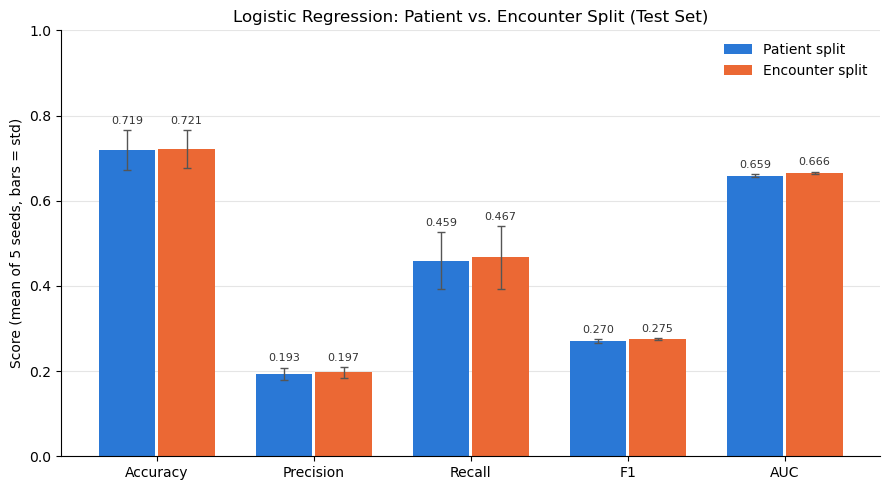

In [13]:
patient_color, encounter_color = '#2a78d6', '#eb6834'
means = results.groupby('Split', sort=False)[metric_cols].mean()
stds = results.groupby('Split', sort=False)[metric_cols].std()

x = np.arange(len(metric_cols))
width = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
for offset, name, color in [(-width / 2, 'Patient split', patient_color),
                            (width / 2, 'Encounter split', encounter_color)]:
    bars = ax.bar(x + offset, means.loc[name], width - 0.02, yerr=stds.loc[name],
                  color=color, label=name, capsize=3, error_kw={'elinewidth': 1, 'ecolor': '#555555'})
    for bar, value, std in zip(bars, means.loc[name], stds.loc[name]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + std + 0.015, f'{value:.3f}',
                ha='center', fontsize=8, color='#333333')

ax.set_xticks(x)
ax.set_xticklabels(metric_cols)
ax.set_ylim(0, 1)
ax.set_ylabel('Score (mean of 5 seeds, bars = std)')
ax.set_title('Logistic Regression: Patient vs. Encounter Split (Test Set)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e5e5e5')
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Cross Validation Both Ways
As another check, I ran 5-fold stratified cross validation on all the data, once with ordinary folds
(`StratifiedKFold`, encounters split freely) and once with folds grouped by patient (`StratifiedGroupKFold`),
using C = 0.1 from the main notebook.

In [14]:
cv_rows = []
keep = valid_gender.to_numpy()
for name, cv in [('Encounter folds (StratifiedKFold)', StratifiedKFold(n_splits=5, shuffle=True, random_state=42)),
                 ('Patient folds (StratifiedGroupKFold)', StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42))]:
    # groups are only used by the patient-grouped folds
    fold_groups = groups[keep] if isinstance(cv, StratifiedGroupKFold) else None
    scores = cross_validate(make_model(0.1), X[keep], y[keep], groups=fold_groups, cv=cv,
                            scoring=['precision', 'recall', 'f1', 'roc_auc'])
    cv_rows.append({'Folds': name,
                    **{m: f"{scores['test_' + m].mean():.3f} +/- {scores['test_' + m].std():.3f}"
                       for m in ['precision', 'recall', 'f1', 'roc_auc']}})
print(pd.DataFrame(cv_rows).to_string(index=False))

                               Folds       precision          recall              f1         roc_auc
   Encounter folds (StratifiedKFold) 0.183 +/- 0.002 0.548 +/- 0.012 0.275 +/- 0.004 0.665 +/- 0.007
Patient folds (StratifiedGroupKFold) 0.183 +/- 0.004 0.546 +/- 0.010 0.274 +/- 0.006 0.665 +/- 0.003


## Does Seeing a Patient's Other Encounters Help?
This is the main question behind the suggestion. If the model learned something useful from a patient's other
encounters, then encounters from **repeat patients** should be predicted better with the encounter split
(where their other visits are in training) than with the patient split (where they are not).

In [15]:
subgroups = ['AUC repeat patients', 'AUC one-visit patients']
print(results.groupby('Split', sort=False)[subgroups].agg(['mean', 'std']).round(4).T.to_string())

encounter_only = results[results['Split'] == 'Encounter split']
print("\nEncounter split only - test encounters of patients seen in training vs. new patients:")
print(encounter_only[['AUC seen patients', 'AUC new patients']].agg(['mean', 'std']).round(4).to_string())

Split                        Patient split  Encounter split
AUC repeat patients    mean         0.5568           0.5625
                       std          0.0046           0.0050
AUC one-visit patients mean         0.7041           0.7077
                       std          0.0093           0.0143

Encounter split only - test encounters of patients seen in training vs. new patients:
      AUC seen patients  AUC new patients
mean             0.5638            0.6864
std              0.0071            0.0090


## Concluding Thoughts
* **The split barely changes the results.** Averaged over 5 seeds, the encounter split scored slightly higher:
  AUC **0.666 vs. 0.659** and F1 **0.275 vs. 0.270**. Precision, recall and accuracy differences are all
  smaller than the seed-to-seed variation. With 5-fold cross validation the two are identical
  (AUC 0.665 both ways, F1 0.275 vs. 0.274).
* **Seeing a patient's other encounters helps very little.** With the encounter split, ~41% of the test
  encounters belong to patients who are also in training. On encounters from repeat patients, AUC is
  **0.562** with the encounter split and **0.557** with the patient split, a gain of less than 0.01. Inside the
  encounter split, those "seen" patients (AUC 0.564) are actually predicted much *worse* than new patients
  (AUC 0.686). Logistic regression doesn't get patient IDs and is too simple to memorize individual patients,
  so it can't learn much about a specific patient from their other visits.
* **Repeat patients are the hard part either way.** They are readmitted far more often than one-visit patients,
  but *which* of their visits leads to a readmission is hard to tell from discharge data. AUC is ~0.56 for them
  vs. ~0.70 for one-visit patients under both splits. This matches the teammate's point that the interesting
  question is why the same patient is readmitted after one visit and not another. The current features just
  don't separate those visits well.
* **What I'm keeping:** the patient split stays the main result. The difference is tiny, it's the more cautious
  estimate for patients the hospital has never seen, and it's the split the project proposal and the Random
  Forest use. The encounter-split numbers can go in the report as a check that the choice of split doesn't
  change our conclusions for logistic regression.
* **For the other models:** Random Forest and the neural network can memorize much more than logistic
  regression, so the gap between the two splits could be bigger for them. It would be worth running the same
  comparison on those models before comparing the final numbers.